# URB-02 | Vía Perimetral completa: red vial, dimensiones H‑E‑V y vulnerabilidad del entorno
**Tesis:** Construcción de grafos de red urbana para cuantificar exposición, conectividad y criticidad en zonas de riesgo.

**Zona de estudio:** todo el corredor de la Vía Perimetral de Guayaquil. Se usan los mismos tramos de 500 m del pipeline (`datasetDim_H`) y la red vial OSM dentro de una franja de ±400 m alrededor del eje.

**Fuentes**
| Fuente | Uso |
|---|---|
| `Dataset_Limpio` (Supabase) | Siniestros 2024‑2026 de la Perimetral (876 eventos únicos, ya depurados) |
| `datasetDim_H` (Supabase) | Tramos de 500 m del eje (geometría y nodos), los mismos del pipeline |
| OpenStreetMap (OSMnx) | Red vial del corredor: nodos, aristas e intersecciones |
| `censo_sectores` (Supabase) | Censo INEC 2022 por sector censal + polígonos. La primera vez se carga desde `censo_sectores_guayaquil.geojson` |

**Tablas que escribe en Supabase** (con la secret key): `censo_sectores` (solo la 1.ª vez), `censo_tramos`, `censo_tramos_lados` y `urb02_tramos_hev`.

**Qué entrega**
1. La red vial del corredor como grafo, con dos métricas: centralidad de intermediación y caída de eficiencia.
2. Los siniestros asociados a los tramos y a las calles OSM.
3. El perfil de vulnerabilidad del entorno: porcentaje de adultos mayores, niños, personas con discapacidad grave y pobreza por NBI, **comparando adentro y afuera de la vía** y con el promedio de Guayaquil urbano.
4. Las dimensiones **H** (peligrosidad), **E** (exposición) y **V** (vulnerabilidad), cada una con un componente de siniestros y otro del entorno, más la criticidad.
5. Tablas de porcentajes por nivel de vulnerabilidad, mapas interactivos, un mapa estático para el informe y las exportaciones.

## 1. Configuración y rutas

In [ ]:
!pip install -q osmnx supabase geopandas folium branca

In [1]:
import os, json, time, warnings
from pathlib import Path
from datetime import datetime
import numpy as np, pandas as pd, geopandas as gpd
import networkx as nx, osmnx as ox
import matplotlib.pyplot as plt, matplotlib.colors as mcolors
import folium, branca
from shapely.geometry import Point, mapping
from IPython.display import display
from supabase import create_client
warnings.filterwarnings('ignore', category=UserWarning)

# --- Supabase ---
SUPABASE_URL = 'https://myvmerqmopraucubddrx.supabase.co'
SUPABASE_PUBLISHABLE = 'sb_publishable_hq301zTmsrs-Eq18e5qwQw_XZRo9z-X'     # pública, solo lectura
def _secret():
    try:
        from google.colab import userdata
        return userdata.get('SUPABASE_SECRET_KEY')
    except Exception:
        return os.getenv('SUPABASE_SECRET_KEY')
sb_lectura = create_client(SUPABASE_URL, SUPABASE_PUBLISHABLE)
_SK = _secret()
sb_escritura = create_client(SUPABASE_URL, _SK) if _SK else None

# --- mapa base CARTO (con API key, sin marca de agua) ---
CARTO_KEY = 'cb1_5do9_1_90e38ab2e2043b7ab55c5b13'
TILES_CARTO = 'https://basemaps.cartocdn.com/rastertiles/light_all/{z}/{x}/{y}.png?key=' + CARTO_KEY
ATTR_CARTO = '© OpenStreetMap contributors © CARTO'

# --- rutas ---
OUT = Path('resultados_urb02_perimetral_hev'); OUT.mkdir(exist_ok=True)
ARCHIVO_CENSO = 'censo_sectores_guayaquil.geojson'      # solo la 1.ª vez: luego se lee de Supabase (censo_sectores)
CENTRO_CIUDAD = (-2.1894, -79.8870)   # centro de Guayaquil (Malecón): define el lado 'adentro' de la vía

# --- parámetros ---
LONGITUD_TRAMO_M      = 500     # longitud de cada tramo (arista del eje)
DISTANCIA_MAX_M       = 250     # siniestro → tramo más cercano, hasta esta distancia
TOLERANCIA_NODO_M     = 30      # extremos de tramo más cercanos que esto = mismo nodo
CORREDOR_RED_M        = 400     # franja a cada lado del eje para descargar la red OSM
UMBRAL_ASOCIACION_M   = 60      # siniestro → calle OSM; nodos OSM → tramo (exploratorio)
RADIO_INFLUENCIA_M    = 300     # área de influencia de cada tramo para el censo
MUESTRA_INTERMEDIACION = 600    # nodos fuente para aproximar la intermediación (red grande)
RADIO_EFICIENCIA_M    = 800     # subred local para medir la caída de eficiencia
TOP_CRITICOS          = 5       # nodos más centrales en los que se prueba la interrupción
SUAVIZADO             = 5
UMBRALES              = (0.33, 0.66)   # Baja < 0.33 ≤ Media < 0.66 ≤ Alta
PESOS                 = {'H': 1/3, 'E': 1/3, 'V': 1/3}
PESO_ENTORNO          = 0.5     # peso del componente de entorno dentro de cada dimensión
HORAS_PICO            = {6, 7, 8, 17, 18, 19}
CRS_METROS            = 32717   # UTM 17S
VEH = ['automovil', 'bicicleta', 'bus', 'camion', 'camioneta', 'emergencias', 'especial', 'furgoneta',
       'motocicleta', 'no_identificado', 'scooter_electrico', 'tricimoto', 'vehiculo_deportivo_utilitario']

ox.settings.use_cache = True
ox.settings.requests_timeout = 180
print('OSMnx:', ox.__version__, '| NetworkX:', nx.__version__)
print('Supabase lectura: OK · escritura:', 'OK' if sb_escritura else 'no (opcional: SUPABASE_SECRET_KEY en Secrets)')
print('Resultados en:', OUT.resolve())

# --- acceso a Supabase ---
LOTE = 300
def leer(tabla, orden):
    filas, desde = [], 0
    while True:
        r = sb_lectura.table(tabla).select('*').order(orden).range(desde, desde + 999).execute().data
        filas += r
        if len(r) < 1000:
            return pd.DataFrame(filas)
        desde += 1000

def contar(tabla, col):
    return sb_lectura.table(tabla).select(col, count='exact').limit(1).execute().count or 0

def a_registros(df):
    out = df.copy()
    for c in out.columns:
        if pd.api.types.is_datetime64_any_dtype(out[c]):
            out[c] = out[c].map(lambda x: x.isoformat() if pd.notna(x) else None)
    out = out.astype(object).where(pd.notna(out), None)
    conv = lambda o: o.item() if hasattr(o, 'item') else str(o)
    return json.loads(json.dumps(out.to_dict('records'), default=conv))

def reemplazar(tabla, df, pk):
    if sb_escritura is None:
        print(f'(sin SUPABASE_SECRET_KEY: no se guardó {tabla} en Supabase)'); return
    sb_escritura.table(tabla).delete().neq(pk, '__ninguno__').execute()
    regs = a_registros(df)
    for i in range(0, len(regs), LOTE):
        for intento in range(3):
            try:
                sb_escritura.table(tabla).insert(regs[i:i + LOTE]).execute(); break
            except Exception:
                if intento == 2: raise
                time.sleep(2 * (intento + 1))
    print(f'✔ {tabla}: {len(regs)} filas guardadas en Supabase')

ModuleNotFoundError: No module named 'networkx'

## 2. Modelo conceptual
| Elemento | Definición |
|---|---|
| **Tramo** (arista del eje) | Pedazo de ~500 m de la Perimetral. Es la unidad donde se calculan H, E, V y la criticidad. |
| **Nodo del eje** | Extremo de un tramo. Los extremos a menos de 30 m entre sí se fusionan. |
| **Red OSM del corredor** | Grafo dirigido de calles transitables a ±400 m del eje: nodos = intersecciones (`osmid`, `street_count`) y aristas = calles (`length`, `name`, `oneway`). |
| **Área de influencia** | Franja de 300 m a cada lado del tramo, que se cruza con los sectores censales. |

Cada dimensión combina dos componentes, con pesos `1 − PESO_ENTORNO` y `PESO_ENTORNO`:

| Dimensión | Componente de siniestros (`Dataset_Limpio`) | Componente de entorno |
|---|---|---|
| **H** Peligrosidad | velocidad, intersecciones conflictivas, geometría vial, visibilidad | densidad de intersecciones OSM (nodos con 3 o más calles por km) |
| **E** Exposición | vehículos/km, hora pico, flujo peatonal | densidad de población (censo) + intermediación máxima de la red |
| **V** Vulnerabilidad | letalidad, lesividad, cruce sin protección, usuarios vulnerables | % de 65 años o más, % de menores de 15, % con discapacidad grave, % pobreza NBI (censo) |

Cada indicador se normaliza con min-max entre tramos. Cada componente es el promedio de sus indicadores, y la dimensión es la combinación de los dos componentes, reescalada otra vez de 0 a 1 entre tramos para que los niveles Baja, Media y Alta sean comparables. En los tramos sin siniestros, el componente de siniestros vale 0 y solo cuenta el entorno. **No se infiere causalidad.**

## 3. Cargar `Dataset_Limpio` desde Supabase

In [ ]:
DL = leer('Dataset_Limpio', 'id_siniestro')
if DL.empty:
    if os.path.exists('Dataset_Limpio.csv'):
        DL = pd.read_csv('Dataset_Limpio.csv')
    else:
        raise RuntimeError('Dataset_Limpio está vacío en Supabase. Ejecuta antes el notebook '
                           'RISKTWIN_Pipeline_Supabase_HEV (secciones 1 a 4), o sube Dataset_Limpio.csv.')
DL['fecha_hora'] = pd.to_datetime(DL['fecha_hora'], utc=True).dt.tz_convert('America/Guayaquil')
DL['hora_num'] = DL['fecha_hora'].dt.hour
for c in VEH + ['lesionados', 'fallecidos', 'total_vehiculos']:
    DL[c] = pd.to_numeric(DL[c], errors='coerce').fillna(0).astype(int)
gdl = gpd.GeoDataFrame(DL, geometry=gpd.points_from_xy(DL['longitud'], DL['latitud']), crs=4326).to_crs(CRS_METROS)
print(f'{len(gdl)} siniestros únicos · {int(DL.fallecidos.sum())} fallecidos · {int(DL.lesionados.sum())} lesionados')
display(DL.groupby('anio').agg(siniestros=('id_siniestro', 'size'), fallecidos=('fallecidos', 'sum'),
                               lesionados=('lesionados', 'sum')))

876 siniestros únicos · 119 fallecidos · 846 lesionados


,siniestros,fallecidos,lesionados
anio,,,
2024,386,44,383
2025,364,53,355
2026,126,22,108


## 4. Tramos de 500 m y nodos del eje (desde Supabase)
Se usan **los mismos tramos** del notebook del pipeline: se leen de `datasetDim_H` (identificador, geometría y nodos). Así los resultados de URB-02 se pueden comparar tramo a tramo con las dimensiones ya guardadas. Ya no hace falta descargar el eje de Overpass.

In [ ]:
from shapely.geometry import shape
TR = leer('datasetDim_H', 'tramo')
if TR.empty:
    raise RuntimeError('datasetDim_H está vacía. Ejecuta antes el notebook RISKTWIN_Pipeline_Supabase_HEV completo.')
tramos = gpd.GeoDataFrame(TR[['tramo', 'pieza', 'longitud_m', 'nodo_inicio', 'nodo_fin']],
                          geometry=[shape(g) for g in TR['geometria']], crs=4326).to_crs(CRS_METROS)
tramos['longitud_m'] = tramos.length.round(1)
eje = list(tramos.geometry)

# nodos del eje (extremos de los tramos)
pts = pd.concat([pd.DataFrame({'nodo': tramos['nodo_inicio'], 'geometry': [Point(g.coords[0]) for g in tramos.geometry]}),
                 pd.DataFrame({'nodo': tramos['nodo_fin'], 'geometry': [Point(g.coords[-1]) for g in tramos.geometry]})])
nodos_eje = gpd.GeoDataFrame(pts.drop_duplicates('nodo'), geometry='geometry', crs=CRS_METROS)
nodos_eje['grado'] = nodos_eje['nodo'].map(pts['nodo'].value_counts()).astype(int)

# siniestro → tramo
asig = gpd.sjoin_nearest(gdl, tramos[['tramo', 'geometry']], how='left', max_distance=DISTANCIA_MAX_M, distance_col='dist_tramo_m')
gdl = asig.sort_values('dist_tramo_m').drop_duplicates('id_siniestro').drop(columns='index_right')
d = gdl[gdl['tramo'].notna()].copy()
print(f'{len(tramos)} tramos · {len(nodos_eje)} nodos del eje · {tramos.length.sum()/1000:.1f} km de calzadas')
print(f'{len(d)} de {len(gdl)} siniestros asignados a un tramo ({len(d)/len(gdl):.0%}); '
      f'el resto está a más de {DISTANCIA_MAX_M} m del eje')

88 tramos · 74 nodos del eje · 43.0 km de calzadas
816 de 876 siniestros asignados a un tramo (93%); el resto está a más de 250 m del eje


## 5. Red vial OSM del corredor (grafo)
Se descarga la red de calles transitables (`network_type="drive"`) dentro de una franja de ±400 m alrededor del eje. Se guarda en GraphML para reutilizarla.

In [ ]:
archivo_grafo = OUT / 'red_corredor_perimetral.graphml'
corredor = gpd.GeoSeries([gpd.GeoSeries(eje, crs=CRS_METROS).union_all().buffer(CORREDOR_RED_M)], crs=CRS_METROS)
poligono = corredor.to_crs(4326).iloc[0]
if archivo_grafo.exists():
    G = ox.load_graphml(filepath=str(archivo_grafo))
    print('Se reutilizó la red local:', archivo_grafo)
else:
    G, errores = None, []
    for servidor in ['https://overpass-api.de/api', 'https://overpass.kumi.systems/api',
                     'https://maps.mail.ru/osm/tools/overpass/api']:
        try:
            ox.settings.overpass_url = servidor
            print('Consultando', servidor, '(puede tardar 1-3 min)')
            G = ox.graph_from_polygon(poligono, network_type='drive', simplify=True, retain_all=False)
            break
        except Exception as exc:
            errores.append(f'{servidor}: {str(exc)[:160]}'); print('Falló:', str(exc)[:160])
    if G is None:
        raise RuntimeError('No se pudo descargar OSM. Reintenta luego.\n' + '\n'.join(errores))
    ox.save_graphml(G, filepath=str(archivo_grafo))
print('Red OSM del corredor:', G.number_of_nodes(), 'nodos,', G.number_of_edges(), 'aristas dirigidas')

Consultando https://overpass-api.de/api (puede tardar 1-3 min)
Red OSM del corredor: 2307 nodos, 6072 aristas dirigidas


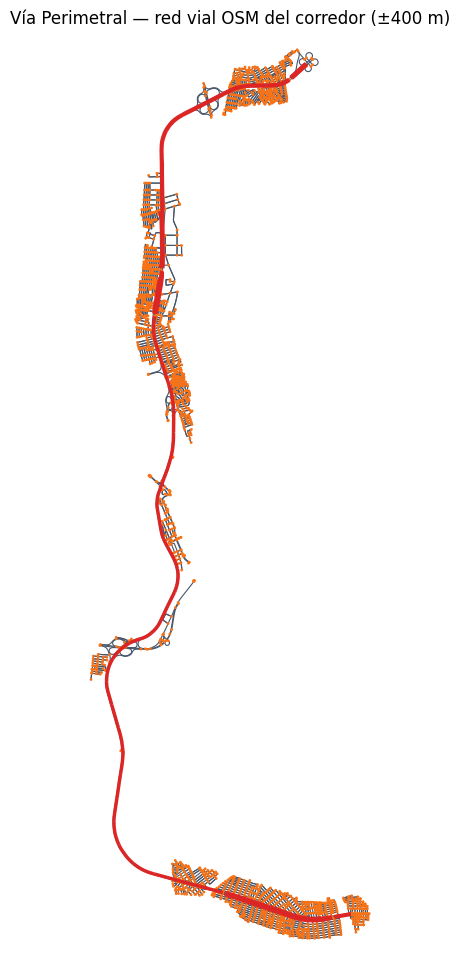

Nodos y aristas OSM exportados.


In [ ]:
nodos_osm, aristas_osm = ox.graph_to_gdfs(G)
fig, ax = ox.plot.plot_graph(G, node_size=4, node_color='#f97316', edge_color='#475569', edge_linewidth=0.8,
                             bgcolor='white', show=False, close=False, figsize=(9, 12))
gpd.GeoSeries(eje, crs=CRS_METROS).to_crs(4326).plot(ax=ax, color='#dc2626', linewidth=2.5)
ax.set_title('Vía Perimetral — red vial OSM del corredor (±%d m)' % CORREDOR_RED_M)
fig.savefig(OUT / 'mapa_red_vial_corredor.png', dpi=200, bbox_inches='tight'); plt.show()
nodos_osm.reset_index().drop(columns='geometry').to_csv(OUT / 'nodos_osm.csv', index=False, encoding='utf-8-sig')
aristas_osm.reset_index().drop(columns='geometry').to_csv(OUT / 'aristas_osm.csv', index=False, encoding='utf-8-sig')
print('Nodos y aristas OSM exportados.')

## 6. Métrica 1: centralidad de intermediación
Mide en qué proporción de las rutas más cortas (por longitud) participa cada intersección. La red del corredor es grande, así que se aproxima con una muestra de `MUESTRA_INTERMEDIACION` nodos fuente (semilla fija, para que el resultado se pueda reproducir). **No equivale a probabilidad de siniestro.**

Intermediación calculada sobre 2307 nodos (muestra k=600) en 11 s


,nodo_osm,intermediacion,calles,latitud,longitud
1603,595147871,0.271368,3,-2.138900,-79.945994
3,315367583,0.270601,3,-2.140829,-79.945712
679,411692955,0.257460,4,-2.232972,-79.943043
1950,4309417765,0.257009,3,-2.130354,-79.948622
1026,585197328,0.256588,3,-2.130115,-79.948697
2291,13052286328,0.255955,3,-2.130397,-79.948609
2041,5204181824,0.254279,3,-2.129242,-79.948968
2145,9634773158,0.252861,3,-2.155157,-79.947650
1900,4238046626,0.252623,3,-2.134708,-79.947248
789,415652304,0.252440,3,-2.151843,-79.946484


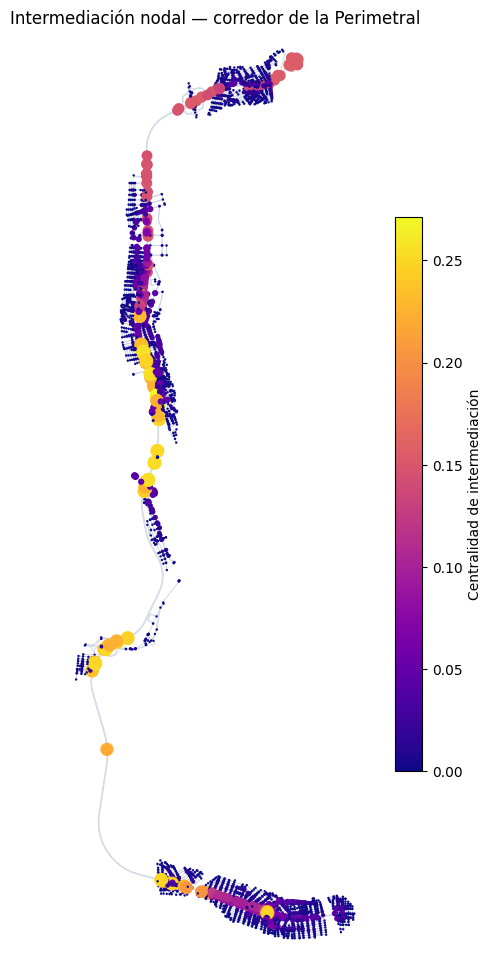

In [ ]:
mayor = max(nx.weakly_connected_components(G), key=len)
D = ox.convert.to_digraph(G.subgraph(mayor).copy(), weight='length')
k = min(MUESTRA_INTERMEDIACION, D.number_of_nodes())
t0 = time.time()
bc = nx.betweenness_centrality(D, k=k, weight='length', normalized=True, seed=42)
print(f'Intermediación calculada sobre {D.number_of_nodes()} nodos (muestra k={k}) en {time.time()-t0:.0f} s')
nodos_osm['intermediacion'] = nodos_osm.index.map(bc).fillna(0.0)
ranking = (nodos_osm.reset_index()[['osmid', 'intermediacion', 'street_count', 'y', 'x']]
           .rename(columns={'osmid': 'nodo_osm', 'y': 'latitud', 'x': 'longitud', 'street_count': 'calles'})
           .sort_values('intermediacion', ascending=False))
display(ranking.head(10))
ranking.to_csv(OUT / 'ranking_intermediacion.csv', index=False, encoding='utf-8-sig')

valores = [bc.get(n, 0) for n in G.nodes]
norm = mcolors.Normalize(vmin=0, vmax=max(valores) or 1)
cm_ = plt.get_cmap('plasma')
fig, ax = ox.plot.plot_graph(G, node_size=[3 + 400 * v for v in valores], node_color=[cm_(norm(v)) for v in valores],
                             edge_color='#cbd5e1', edge_linewidth=0.6, bgcolor='white', show=False, close=False, figsize=(9, 12))
sm = plt.cm.ScalarMappable(norm=norm, cmap=cm_); sm.set_array([])
fig.colorbar(sm, ax=ax, label='Centralidad de intermediación', shrink=0.6)
ax.set_title('Intermediación nodal — corredor de la Perimetral')
fig.savefig(OUT / 'mapa_intermediacion.png', dpi=200, bbox_inches='tight'); plt.show()

## 7. Métrica 2: caída de eficiencia al interrumpir los nodos más centrales
Para cada uno de los `TOP_CRITICOS` nodos con mayor intermediación se toma su subred local (radio de 800 m por la red) y se calcula la eficiencia global ponderada: el promedio de 1/distancia entre pares de nodos, donde los pares sin ruta aportan 0. Luego se aíslan las conexiones del nodo, conservando el mismo conjunto de nodos, y se mide cuánto cae la eficiencia.

In [ ]:
def eficiencia_global_ponderada(Dg):
    n = Dg.number_of_nodes()
    if n < 2:
        return 0.0
    total = 0.0
    for o, destinos in nx.all_pairs_dijkstra_path_length(Dg, weight='length'):
        total += sum(1.0 / dist for dest, dist in destinos.items() if dest != o and dist > 0)
    return total / (n * (n - 1))

filas = []
for nodo in ranking['nodo_osm'].head(TOP_CRITICOS):
    sub = nx.ego_graph(D, nodo, radius=RADIO_EFICIENCIA_M, distance='length', undirected=True).copy()
    e0 = eficiencia_global_ponderada(sub)
    sub.remove_edges_from(list(sub.in_edges(nodo)) + list(sub.out_edges(nodo)))
    e1 = eficiencia_global_ponderada(sub)
    filas.append({'nodo_osm': nodo, 'intermediacion': bc[nodo], 'nodos_subred': sub.number_of_nodes(),
                  'eficiencia_base_1_por_m': e0, 'eficiencia_nodo_aislado_1_por_m': e1,
                  'reduccion_eficiencia_pct': 100 * (e0 - e1) / e0 if e0 > 0 else np.nan,
                  'latitud': G.nodes[nodo]['y'], 'longitud': G.nodes[nodo]['x']})
eficiencia = pd.DataFrame(filas)
display(eficiencia.round(5))
eficiencia.to_csv(OUT / 'eficiencia_nodos_criticos.csv', index=False, encoding='utf-8-sig')

,nodo_osm,intermediacion,nodos_subred,eficiencia_base_1_por_m,eficiencia_nodo_aislado_1_por_m,reduccion_eficiencia_pct,latitud,longitud
0,595147871,0.27137,127,0.00265,0.00261,1.48515,-2.13890,-79.94599
1,315367583,0.27060,88,0.00224,0.00217,2.87274,-2.14083,-79.94571
2,411692955,0.25746,159,0.00234,0.00191,18.23059,-2.23297,-79.94304
3,4309417765,0.25701,128,0.00259,0.00236,8.74307,-2.13035,-79.94862
4,585197328,0.25659,127,0.00260,0.00243,6.79076,-2.13011,-79.94870


## 8. Siniestros asociados a calles OSM y nodos OSM por tramo
- Cada siniestro se asocia a la **calle OSM** más cercana, hasta `UMBRAL_ASOCIACION_M`. Es un umbral exploratorio: **cercanía no prueba la localización exacta**.
- Cada tramo recibe sus **intersecciones OSM**, que son los nodos con 3 o más calles a menos de 60 m, y la intermediación máxima entre ellas.

In [ ]:
ar_m = aristas_osm.to_crs(CRS_METROS).reset_index()[['u', 'v', 'key', 'name', 'length', 'geometry']]
ar_m['name'] = ar_m['name'].map(lambda n: ', '.join(map(str, n)) if isinstance(n, list) else n)
aso = gpd.sjoin_nearest(gdl[['id_siniestro', 'geometry']], ar_m, how='left',
                        max_distance=UMBRAL_ASOCIACION_M, distance_col='dist_calle_m')
aso = aso.sort_values('dist_calle_m').drop_duplicates('id_siniestro')
print(f'Siniestros a ≤{UMBRAL_ASOCIACION_M} m de una calle OSM del corredor: {aso.u.notna().sum()} de {len(gdl)}')
conteo_calles = (aso.dropna(subset=['u']).groupby(['u', 'v', 'key']).size().rename('siniestros_cercanos').reset_index())
calles = ar_m.merge(conteo_calles, on=['u', 'v', 'key'], how='left').fillna({'siniestros_cercanos': 0})
calles['siniestros_cercanos'] = calles['siniestros_cercanos'].astype(int)
display(calles.drop(columns='geometry').sort_values('siniestros_cercanos', ascending=False).head(10))
calles.to_crs(4326).to_file(OUT / 'calles_osm_con_siniestros.geojson', driver='GeoJSON')

# nodos OSM → tramo
no_m = nodos_osm.to_crs(CRS_METROS)
cerca = gpd.sjoin(no_m[['street_count', 'intermediacion', 'geometry']],
                  gpd.GeoDataFrame(tramos[['tramo']], geometry=tramos.buffer(UMBRAL_ASOCIACION_M), crs=CRS_METROS),
                  predicate='within')
red_tramo = cerca.groupby('tramo').agg(intersecciones=('street_count', lambda s: int((s >= 3).sum())),
                                       intermediacion_max=('intermediacion', 'max'))
print('Tramos con intersecciones OSM:', (red_tramo.intersecciones > 0).sum(), 'de', len(tramos))

Siniestros a ≤60 m de una calle OSM del corredor: 827 de 876


,u,v,key,name,length,siniestros_cercanos
5495,4319893139,3915622273,0,Vía Perimetral,5482.438569,35
5133,3210186833,4300946022,0,Vía Perimetral,3503.078088,28
5745,9258142979,5103484605,0,Vía Perimetral,3825.751034,26
6042,11328387964,585044605,0,Vía Perimetral,1275.536774,21
5792,10784775183,411692884,0,Vía Perimetral,3645.199335,18
5021,1814881324,343121280,0,Vía Perimetral,564.033342,16
5245,4193763311,315367595,0,Vía Perimetral,960.879109,16
5201,3743116419,3743119437,0,Vía Perimetral,336.245900,13
2267,415652310,316514238,0,Vía Perimetral,679.118176,12
5044,1814881341,1814881333,0,Vía Perimetral,579.067840,12


Tramos con intersecciones OSM: 73 de 88


## 9. Vulnerabilidad del entorno: censo INEC 2022 por tramo
Los 6.412 sectores censales urbanos de Guayaquil, con sus indicadores, se leen de la tabla **`censo_sectores`** de Supabase. La primera vez la tabla está vacía: el notebook la llena desde `censo_sectores_guayaquil.geojson` (súbelo a Colab) usando la secret key, y desde entonces ya no necesitas el archivo. Para cada tramo:
1. Se traza el área de influencia de ±300 m.
2. Se cruza con los sectores censales.
3. Cada sector aporta población en proporción al área que cae dentro.
4. Los porcentajes se ponderan por esa población estimada.

Los porcentajes del corredor completo se calculan sobre la **unión** de las áreas de influencia, para no contar dos veces a la misma persona.

✔ censo_sectores: 6412 filas guardadas en Supabase
Población estimada en el corredor (±300 m): 120,009 personas en 397 sectores censales · 34,007 viviendas


,Grupo,Porcentaje,Personas estimadas
0,Adultos mayores (65+),6.4%,"7,633"
1,Niños y adolescentes (<15),26.4%,"31,628"
2,Discapacidad grave,4.3%,"5,164"
3,Dificultad para caminar,2.6%,"3,142"
4,Pobreza por NBI,26.9%,"32,234"
5,Sin instrucción (15+),1.9%,"2,248"


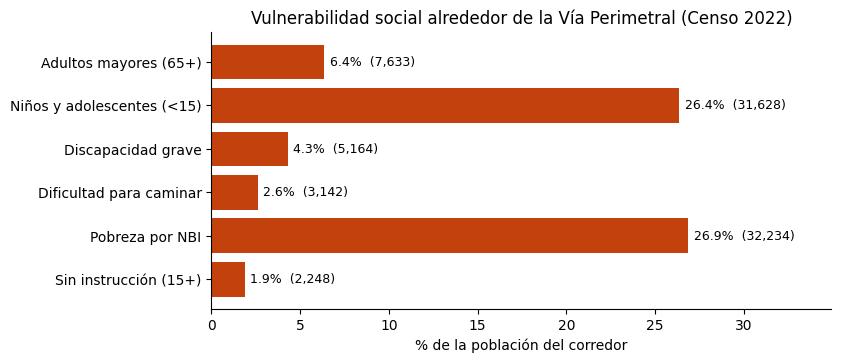

,tramo,n_sectores,poblacion_influencia,viviendas_influencia,pct_65mas,pct_menor15,pct_discapacidad_grave,pct_dificultad_caminar,pct_pobreza_nbi,pct_sin_instruccion_15mas,densidad_hab_km2
26,T027,43,12717,3552,0.051,0.275,0.036,0.021,0.388,0.023,22032.668
5,T006,42,12588,3532,0.052,0.275,0.036,0.021,0.386,0.023,21809.037
67,T068,44,12185,3513,0.056,0.276,0.059,0.040,0.263,0.017,20216.404
69,T070,45,11514,3266,0.054,0.282,0.043,0.027,0.272,0.016,19103.074
85,T086,41,11112,3161,0.059,0.279,0.064,0.043,0.262,0.019,19520.545
80,T081,42,11032,3139,0.059,0.278,0.064,0.044,0.263,0.019,19431.104
71,T072,41,10999,3129,0.059,0.278,0.064,0.044,0.265,0.019,19418.601
84,T085,44,10973,3170,0.057,0.278,0.057,0.038,0.263,0.016,19274.253
68,T069,43,10940,3169,0.053,0.280,0.049,0.031,0.255,0.017,18150.019
82,T083,40,10902,3087,0.054,0.286,0.042,0.026,0.274,0.016,19150.205


In [ ]:
from shapely.geometry import shape
CENSO_COLS = ['cod_sector', 'zona', 'sector', 'poblacion', 'viviendas', 'pct_65mas', 'pct_menor15', 'pct_discapacidad_grave',
              'pct_dificultad_caminar', 'pct_pobreza_nbi', 'pct_sin_instruccion_15mas', 'area_m2']
if contar('censo_sectores', 'cod_sector') > 0:
    cs = leer('censo_sectores', 'cod_sector')
    sec = gpd.GeoDataFrame(cs[CENSO_COLS], geometry=[shape(g) for g in cs['geometria']], crs=4326)
    print(f'censo_sectores leído de Supabase: {len(sec)} sectores')
else:
    if not os.path.exists(ARCHIVO_CENSO):
        from google.colab import files
        print(f'censo_sectores está vacía: selecciona {ARCHIVO_CENSO} para subirlo…')
        ARCHIVO_CENSO = list(files.upload().keys())[0]
    sec = gpd.read_file(ARCHIVO_CENSO).to_crs(4326)
    subir = pd.DataFrame(sec[CENSO_COLS])
    for c in ['poblacion', 'viviendas']:
        subir[c] = subir[c].astype(int)
    subir['geometria'] = [mapping(g) for g in sec.geometry]
    reemplazar('censo_sectores', subir, 'cod_sector')
sec = sec.to_crs(CRS_METROS)
sec['area_sector'] = sec.area
PCT = {'pct_65mas': 'Adultos mayores (65+)', 'pct_menor15': 'Niños y adolescentes (<15)',
       'pct_discapacidad_grave': 'Discapacidad grave', 'pct_dificultad_caminar': 'Dificultad para caminar',
       'pct_pobreza_nbi': 'Pobreza por NBI', 'pct_sin_instruccion_15mas': 'Sin instrucción (15+)'}

def cruzar(areas, clave):
    x = gpd.overlay(areas, sec, how='intersection', keep_geom_type=True)
    x['pob_est'] = x['poblacion'] * (x.area / x['area_sector']).clip(0, 1)
    x['viv_est'] = x['viviendas'] * (x.area / x['area_sector']).clip(0, 1)
    for c in PCT:
        x[c + '_w'] = x[c] * x['pob_est']
    g = x.groupby(clave)
    out = pd.DataFrame({'n_sectores': g['cod_sector'].nunique(), 'poblacion_influencia': g['pob_est'].sum(),
                        'viviendas_influencia': g['viv_est'].sum()})
    for c in PCT:
        out[c] = g[c + '_w'].sum() / g['pob_est'].sum()
    return out, x

buf = gpd.GeoDataFrame(tramos[['tramo']], geometry=tramos.buffer(RADIO_INFLUENCIA_M), crs=CRS_METROS)
buf['area_km2'] = buf.area / 1e6
censo_tramos, _ = cruzar(buf, 'tramo')
censo_tramos = buf[['tramo', 'area_km2']].merge(censo_tramos.reset_index(), on='tramo', how='left')
censo_tramos['densidad_hab_km2'] = censo_tramos['poblacion_influencia'] / censo_tramos['area_km2']
censo_tramos = censo_tramos.drop(columns='area_km2')
for c in ['n_sectores', 'poblacion_influencia', 'viviendas_influencia']:
    censo_tramos[c] = censo_tramos[c].fillna(0).round(0).astype(int)

# corredor completo (unión de áreas, sin doble conteo)
union = gpd.GeoDataFrame({'ambito': ['Corredor Perimetral']}, geometry=[buf.union_all()], crs=CRS_METROS)
tot, piezas_corr = cruzar(union, 'ambito')
pob_corr = tot['poblacion_influencia'].iat[0]
perfil = pd.DataFrame([{'Grupo': et, 'Porcentaje': tot[c].iat[0], 'Personas estimadas': round(tot[c].iat[0] * pob_corr)}
                       for c, et in PCT.items()])
print(f'Población estimada en el corredor (±{RADIO_INFLUENCIA_M} m): {pob_corr:,.0f} personas '
      f'en {tot.n_sectores.iat[0]} sectores censales · {tot.viviendas_influencia.iat[0]:,.0f} viviendas')
display(perfil.style.format({'Porcentaje': '{:.1%}', 'Personas estimadas': '{:,.0f}'}))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(perfil['Grupo'][::-1], perfil['Porcentaje'][::-1] * 100, color='#c2410c')
for i, (p, n) in enumerate(zip(perfil['Porcentaje'][::-1], perfil['Personas estimadas'][::-1])):
    ax.text(p * 100 + 0.3, i, f'{p:.1%}  ({n:,.0f})', va='center', fontsize=9)
ax.set_xlabel('% de la población del corredor'); ax.set_xlim(0, perfil['Porcentaje'].max() * 130)
ax.set_title('Vulnerabilidad social alrededor de la Vía Perimetral (Censo 2022)')
ax.spines[['top', 'right']].set_visible(False)
fig.savefig(OUT / 'perfil_vulnerabilidad_corredor.png', dpi=200, bbox_inches='tight'); plt.show()
display(censo_tramos.sort_values('poblacion_influencia', ascending=False).head(10).round(3))

## 9b. Vulnerabilidad adentro vs. afuera de la Vía Perimetral
La Perimetral separa la ciudad consolidada (**adentro**, hacia el centro de Guayaquil) de la periferia (**afuera**: Pascuales, Bastión Popular, Flor de Bastión, Monte Sinaí, Guasmo). Para comparar los dos lados, el área de influencia de cada tramo se parte en dos mitades de 300 m:
- **Adentro:** la mitad cuyo centro queda más cerca del centro de la ciudad (`CENTRO_CIUDAD`).
- **Afuera:** la otra mitad.

Se calculan los mismos porcentajes del censo para cada lado y se comparan entre sí y con el promedio de **Guayaquil urbano**. La brecha se expresa en puntos porcentuales (p.p.) = % afuera − % adentro.

■ Perfil social por lado de la vía (Censo 2022)


,poblacion,Adultos mayores (65+),Niños y adolescentes (<15),Discapacidad grave,Dificultad para caminar,Pobreza por NBI,Sin instrucción (15+)
Adentro (hacia la ciudad),"62,959",7.2%,25.5%,4.4%,2.7%,24.7%,1.8%
Afuera (hacia la periferia),"51,495",5.2%,27.4%,4.1%,2.4%,29.8%,2.0%
Corredor completo,"120,009",6.4%,26.4%,4.3%,2.6%,26.9%,1.9%
Guayaquil urbano,"2,664,520",8.5%,24.7%,4.7%,2.9%,28.0%,1.7%


■ Brecha afuera − adentro (puntos porcentuales)


,Adultos mayores (65+),Niños y adolescentes (<15),Discapacidad grave,Dificultad para caminar,Pobreza por NBI,Sin instrucción (15+)
p.p.,-2.0,1.9,-0.4,-0.3,5.1,0.2


En 49 de 88 tramos la pobreza NBI es mayor afuera que adentro.


,tramo,pob_adentro,pob_afuera,pct_nbi_adentro,pct_nbi_afuera,pct_65mas_adentro,pct_65mas_afuera,pct_menor15_adentro,pct_menor15_afuera,brecha_nbi_pp
17,T018,22.0,374.0,0.104,0.380,0.060,0.027,0.214,0.269,27.553
19,T020,100.0,2096.0,0.090,0.350,0.035,0.048,0.232,0.268,25.922
1,T002,1786.0,460.0,0.075,0.325,0.064,0.055,0.221,0.266,25.068
0,T001,1698.0,524.0,0.078,0.328,0.064,0.053,0.222,0.269,25.006
2,T003,1867.0,390.0,0.070,0.314,0.065,0.059,0.221,0.261,24.365
8,T009,1193.0,35.0,0.081,0.318,0.087,0.071,0.219,0.266,23.636
3,T004,2001.0,346.0,0.069,0.304,0.065,0.061,0.222,0.257,23.508
18,T019,22.0,3211.0,0.104,0.336,0.060,0.042,0.214,0.286,23.214
14,T015,30.0,429.0,0.181,0.380,0.049,0.030,0.226,0.273,19.921
23,T024,1352.0,46.0,0.079,0.258,0.086,0.086,0.221,0.248,17.936


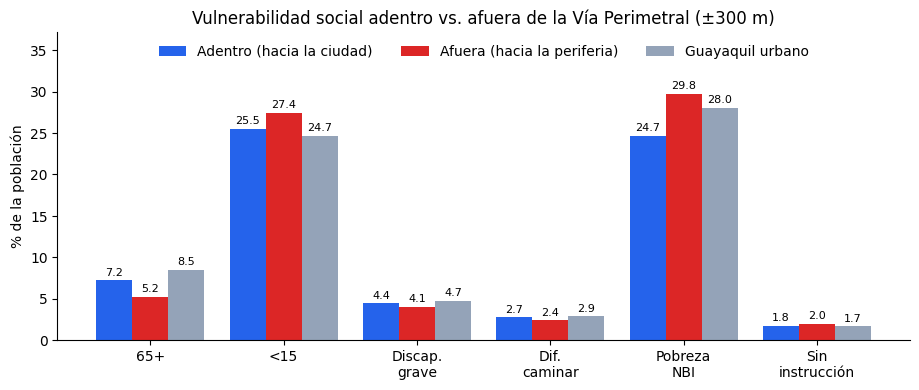

In [ ]:
centro_m = gpd.GeoSeries([Point(CENTRO_CIUDAD[1], CENTRO_CIUDAD[0])], crs=4326).to_crs(CRS_METROS).iloc[0]
filas = []
for t, g in zip(tramos['tramo'], tramos.geometry):
    izq = g.buffer(RADIO_INFLUENCIA_M, single_sided=True)
    der = g.buffer(-RADIO_INFLUENCIA_M, single_sided=True)
    adentro, afuera = (izq, der) if izq.centroid.distance(centro_m) < der.centroid.distance(centro_m) else (der, izq)
    filas += [{'tramo': t, 'lado': 'adentro', 'geometry': adentro}, {'tramo': t, 'lado': 'afuera', 'geometry': afuera}]
lados = gpd.GeoDataFrame(filas, crs=CRS_METROS)
lados['clave'] = lados['tramo'] + '|' + lados['lado']
lados['area_km2'] = lados.area / 1e6

# por tramo y lado
cl, _ = cruzar(lados[['clave', 'geometry']], 'clave')
censo_lados = lados[['tramo', 'lado', 'clave', 'area_km2']].merge(cl.reset_index(), on='clave', how='left')
censo_lados['densidad_hab_km2'] = censo_lados['poblacion_influencia'] / censo_lados['area_km2']
for c in ['n_sectores', 'poblacion_influencia', 'viviendas_influencia']:
    censo_lados[c] = censo_lados[c].fillna(0).round(0).astype(int)

# corredor completo por lado (uniones sin doble conteo) y Guayaquil urbano
u_in = lados[lados.lado == 'adentro'].union_all()
u_out = lados[lados.lado == 'afuera'].union_all().difference(u_in)
tl, _ = cruzar(gpd.GeoDataFrame({'ambito': ['adentro', 'afuera']}, geometry=[u_in, u_out], crs=CRS_METROS), 'ambito')
ciudad = {'poblacion_influencia': sec['poblacion'].sum(),
          **{c: np.average(sec[c].fillna(0), weights=sec['poblacion']) for c in PCT}}
comp = pd.DataFrame({'Adentro (hacia la ciudad)': tl.loc['adentro'], 'Afuera (hacia la periferia)': tl.loc['afuera'],
                     'Corredor completo': tot.iloc[0], 'Guayaquil urbano': pd.Series(ciudad)}).T
comp = comp[['poblacion_influencia'] + list(PCT)].rename(columns={'poblacion_influencia': 'poblacion', **PCT})
brecha = (comp.loc['Afuera (hacia la periferia)', list(PCT.values())] - comp.loc['Adentro (hacia la ciudad)', list(PCT.values())]) * 100
print('■ Perfil social por lado de la vía (Censo 2022)')
display(comp.style.format({'poblacion': '{:,.0f}', **{v: '{:.1%}' for v in PCT.values()}}))
print('■ Brecha afuera − adentro (puntos porcentuales)')
display(brecha.round(1).to_frame('p.p.').T)

# tabla ancha por tramo
ancho = censo_lados.pivot(index='tramo', columns='lado', values=['poblacion_influencia', 'pct_pobreza_nbi', 'pct_65mas', 'pct_menor15'])
ancho.columns = [f'{v}_{l}' for v, l in ancho.columns]
lados_wide = ancho.rename(columns={'poblacion_influencia_adentro': 'pob_adentro', 'poblacion_influencia_afuera': 'pob_afuera',
                                   'pct_pobreza_nbi_adentro': 'pct_nbi_adentro', 'pct_pobreza_nbi_afuera': 'pct_nbi_afuera'}).reset_index()
lados_wide['brecha_nbi_pp'] = (lados_wide['pct_nbi_afuera'] - lados_wide['pct_nbi_adentro']) * 100
n_mas = int((lados_wide['brecha_nbi_pp'] > 0).sum()); n_val = int(lados_wide['brecha_nbi_pp'].notna().sum())
print(f'En {n_mas} de {n_val} tramos la pobreza NBI es mayor afuera que adentro.')
display(lados_wide.sort_values('brecha_nbi_pp', ascending=False).head(10).round(3))

# gráfico
fig, ax = plt.subplots(figsize=(11, 4))
G3 = comp.loc[['Adentro (hacia la ciudad)', 'Afuera (hacia la periferia)', 'Guayaquil urbano'], list(PCT.values())].T * 100
x = np.arange(len(G3)); a = 0.27
for i, (col, color) in enumerate(zip(G3.columns, ['#2563eb', '#dc2626', '#94a3b8'])):
    b = ax.bar(x + (i - 1) * a, G3[col], a, color=color, label=col)
    ax.bar_label(b, fmt='%.1f', fontsize=8, padding=2)
ax.set_xticks(x); ax.set_xticklabels(['65+', '<15', 'Discap.\ngrave', 'Dif.\ncaminar', 'Pobreza\nNBI', 'Sin\ninstrucción'])
ax.set_ylabel('% de la población'); ax.set_title('Vulnerabilidad social adentro vs. afuera de la Vía Perimetral (±300 m)')
ax.set_ylim(0, G3.values.max() * 1.25); ax.legend(ncol=3, loc='upper center', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
fig.savefig(OUT / 'vulnerabilidad_adentro_afuera.png', dpi=200, bbox_inches='tight'); plt.show()

In [ ]:
# mapa de los dos lados
L4 = lados.merge(censo_lados[['clave', 'poblacion_influencia'] + list(PCT)], on='clave').to_crs(4326)
mlados = folium.Map(location=[L4.geometry.centroid.y.mean(), L4.geometry.centroid.x.mean()], zoom_start=12,
                    tiles=TILES_CARTO, attr=ATTR_CARTO)
for col, et, show in [('pct_pobreza_nbi', '% pobreza NBI', True), ('pct_65mas', '% 65+', False),
                      ('pct_menor15', '% <15', False), ('pct_discapacidad_grave', '% discapacidad grave', False)]:
    vmax = float(L4[col].quantile(.95)) or 1
    cm = branca.colormap.LinearColormap(['#fff7ec', '#fc8d59', '#7f0000'], vmin=0, vmax=vmax)
    folium.GeoJson(L4[['tramo', 'lado', 'poblacion_influencia', col, 'geometry']], name=f'Lados · {et}', show=show,
                   style_function=lambda f, c=col, cm=cm, vmax=vmax: {'fillColor': cm(min(f['properties'][c] or 0, vmax)),
                                                                       'fillOpacity': .7, 'color': '#555', 'weight': .4},
                   tooltip=folium.GeoJsonTooltip(['tramo', 'lado', 'poblacion_influencia', col],
                                                 aliases=['Tramo', 'Lado', 'Población', et + ':'])).add_to(mlados)
folium.GeoJson(tramos.to_crs(4326)[['tramo', 'geometry']], name='Eje', style_function=lambda f: {'color': '#111', 'weight': 2}).add_to(mlados)
folium.Marker(list(CENTRO_CIUDAD), tooltip='Centro de la ciudad (define "adentro")', icon=folium.Icon(color='blue', icon='home')).add_to(mlados)
folium.LayerControl(collapsed=False).add_to(mlados)
mlados.save(str(OUT / 'mapa_adentro_afuera.html'))
mlados

## 10. Base común de los tramos y utilidades
Se unen por tramo los siniestros, la red OSM y el censo.

In [ ]:
moda = lambda s: s.mode().iat[0] if not s.mode().empty else None
txt = lambda v, k=None: ('' if v is None or (isinstance(v, float) and np.isnan(v)) else str(v))[:k]
t4 = tramos.to_crs(4326)
base = tramos[['tramo', 'pieza', 'longitud_m', 'nodo_inicio', 'nodo_fin']].copy()
base['lat_centro'] = t4.geometry.interpolate(0.5, normalized=True).y.values
base['lon_centro'] = t4.geometry.interpolate(0.5, normalized=True).x.values
gen = d.groupby('tramo').agg(n_siniestros=('id_siniestro', 'size'), fallecidos=('fallecidos', 'sum'),
                             lesionados=('lesionados', 'sum'), parroquia=('parroquia', moda))
mid = tramos.set_index('tramo').geometry.interpolate(0.5, normalized=True)
ref = (d.assign(_dm=[g.distance(mid[t]) for g, t in zip(d.geometry, d['tramo'])])
         .sort_values('_dm').drop_duplicates('tramo').set_index('tramo')['direccion'].rename('referencia'))
base = (base.merge(gen, on='tramo', how='left').merge(ref, on='tramo', how='left')
            .merge(red_tramo, on='tramo', how='left').merge(censo_tramos, on='tramo', how='left')
            .merge(lados_wide, on='tramo', how='left'))
base[['n_siniestros', 'fallecidos', 'lesionados', 'intersecciones']] = (
    base[['n_siniestros', 'fallecidos', 'lesionados', 'intersecciones']].fillna(0).astype(int))
base['intermediacion_max'] = base['intermediacion_max'].fillna(0.0)
base['parroquia'] = base['parroquia'].fillna('SIN DATO')
base['intersecciones_km'] = base['intersecciones'] / (base['longitud_m'] / 1000)
CON = base['n_siniestros'] > 0

def tasa(casos, p):                       # porcentaje suavizado hacia el promedio de la vía
    return (casos + SUAVIZADO * p) / (base['n_siniestros'] + SUAVIZADO)
def minmax_sin(s):                        # indicadores de siniestros: solo entre tramos con siniestros
    s = s.where(CON); lo, hi = s.min(), s.max()
    return ((s - lo) / (hi - lo) if hi > lo else s * 0).fillna(0.0)
def minmax(s):                            # indicadores de entorno: entre todos los tramos
    lo, hi = s.min(), s.max()
    return ((s - lo) / (hi - lo) if hi > lo else s * 0).fillna(0.0)
def nivel(v):
    return 'Baja' if v < UMBRALES[0] else ('Media' if v < UMBRALES[1] else 'Alta')
def conteo(flag):
    return base['tramo'].map(d[flag].groupby(d['tramo']).sum()).fillna(0).astype(int)
def combinar(sin, ent):
    return minmax((1 - PESO_ENTORNO) * sin.where(CON, 0.0) + PESO_ENTORNO * ent).round(4)   # reescalada 0-1 entre tramos
print(f'{len(base)} tramos · {CON.sum()} con siniestros · {(base.n_sectores > 0).sum()} con datos del censo')

88 tramos · 86 con siniestros · 88 con datos del censo


## 11. Dimensión H — Peligrosidad
| Componente | Indicador | Fuente |
|---|---|---|
| Siniestros | velocidad (C09) · intersecciones conflictivas (choque lateral/frontal, C18, C23, C25, C28) · geometría vial (pérdida de carril/pista, volcamientos, estrellamientos) · visibilidad (18:00–05:59 o C10) | `Dataset_Limpio` |
| Entorno | intersecciones OSM por km (nodos con 3 o más calles) | red OSM |

In [ ]:
d['f_velocidad']    = d['codigo_causa'].eq('C09')
d['f_interseccion'] = d['tipo_siniestro'].isin(['CHOQUE LATERAL', 'CHOQUE FRONTAL']) | d['codigo_causa'].isin(['C18', 'C23', 'C25', 'C28'])
d['f_geometria']    = d['tipo_siniestro'].isin(['PÉRDIDA DE CARRIL', 'PÉRDIDA DE PISTA', 'VOLCAMIENTOS', 'ESTRELLAMIENTOS'])
d['f_visibilidad']  = d['codigo_causa'].eq('C10') | (d['hora_num'] >= 18) | (d['hora_num'] < 6)
H_IND = ['velocidad', 'interseccion', 'geometria', 'visibilidad']
H = base.copy()
for k in H_IND:
    H[f'casos_{k}'] = conteo(f'f_{k}')
    H[f'pct_{k}'] = (H[f'casos_{k}'] / H['n_siniestros']).where(CON)
    H[f'h_{k}_n'] = minmax_sin(tasa(H[f'casos_{k}'], d[f'f_{k}'].mean()))
H['h_siniestros'] = H[[f'h_{k}_n' for k in H_IND]].mean(axis=1)
H['h_entorno'] = minmax(H['intersecciones_km'])
H['valor_h'] = combinar(H['h_siniestros'], H['h_entorno'])
H['nivel_h'] = H['valor_h'].map(nivel)
display(H[['tramo', 'n_siniestros'] + [f'pct_{k}' for k in H_IND] + ['intersecciones_km', 'h_siniestros', 'h_entorno', 'valor_h', 'nivel_h']]
        .sort_values('valor_h', ascending=False).head(10).round(3))

,tramo,n_siniestros,pct_velocidad,pct_interseccion,pct_geometria,pct_visibilidad,intersecciones_km,h_siniestros,h_entorno,valor_h,nivel_h
39,T040,20,0.600,0.250,0.350,0.650,68.871,0.519,1.000,1.000,Alta
65,T066,24,0.667,0.042,0.333,0.542,59.032,0.415,0.857,0.822,Alta
82,T083,7,0.857,0.286,0.571,0.286,48.077,0.549,0.698,0.804,Alta
4,T005,9,0.778,0.000,0.333,0.667,50.865,0.488,0.739,0.790,Alta
78,T079,12,0.500,0.417,0.167,0.833,48.340,0.524,0.702,0.789,Alta
81,T082,4,0.750,0.250,0.500,0.750,43.896,0.578,0.637,0.781,Alta
73,T074,22,0.636,0.636,0.182,0.364,48.564,0.494,0.705,0.770,Alta
36,T037,12,0.583,0.250,0.417,0.583,46.001,0.503,0.668,0.749,Alta
85,T086,5,1.000,0.000,0.200,0.600,45.987,0.485,0.668,0.736,Alta
71,T072,8,0.625,0.250,0.250,0.750,44.341,0.507,0.644,0.735,Alta


## 12. Dimensión E — Exposición
| Componente | Indicador | Fuente |
|---|---|---|
| Siniestros | vehículos involucrados por km · % en hora pico (06–08, 17–19) · % peatonales (atropellos, arrollamientos, caída de pasajero) | `Dataset_Limpio` |
| Entorno | densidad de población en el área de influencia (hab/km²) · intermediación máxima de las intersecciones del tramo | Censo + red OSM |

In [ ]:
d['f_hora_pico'] = d['hora_num'].isin(HORAS_PICO)
d['f_peatonal']  = d['tipo_siniestro'].isin(['ATROPELLOS', 'ARROLLAMIENTOS', 'CAÍDA DE PASAJERO'])
E = base.copy()
E['vehiculos'] = E['tramo'].map(d.groupby('tramo')['total_vehiculos'].sum()).fillna(0).astype(int)
E['vehiculos_km'] = E['vehiculos'] / (E['longitud_m'] / 1000)
E['casos_hora_pico'] = conteo('f_hora_pico'); E['casos_peatonal'] = conteo('f_peatonal')
E['pct_hora_pico'] = (E['casos_hora_pico'] / E['n_siniestros']).where(CON)
E['pct_peatonal'] = (E['casos_peatonal'] / E['n_siniestros']).where(CON)
E['e_siniestros'] = pd.concat([minmax_sin(E['vehiculos_km']),
                               minmax_sin(tasa(E['casos_hora_pico'], d['f_hora_pico'].mean())),
                               minmax_sin(tasa(E['casos_peatonal'], d['f_peatonal'].mean()))], axis=1).mean(axis=1)
E['e_entorno'] = pd.concat([minmax(E['densidad_hab_km2'].fillna(0)), minmax(E['intermediacion_max'])], axis=1).mean(axis=1)
E['valor_e'] = combinar(E['e_siniestros'], E['e_entorno'])
E['nivel_e'] = E['valor_e'].map(nivel)
display(E[['tramo', 'n_siniestros', 'vehiculos_km', 'pct_hora_pico', 'pct_peatonal', 'densidad_hab_km2',
           'intermediacion_max', 'e_siniestros', 'e_entorno', 'valor_e', 'nivel_e']]
        .sort_values('valor_e', ascending=False).head(10).round(3))

,tramo,n_siniestros,vehiculos_km,pct_hora_pico,pct_peatonal,densidad_hab_km2,intermediacion_max,e_siniestros,e_entorno,valor_e,nivel_e
83,T084,8,22.993,0.500,0.625,18469.730,0.246,0.582,0.873,1.000,Alta
64,T065,32,98.386,0.438,0.125,14316.612,0.253,0.591,0.790,0.945,Alta
73,T074,22,73.902,0.500,0.045,18296.006,0.246,0.498,0.869,0.934,Alta
66,T067,22,64.935,0.227,0.455,14915.307,0.231,0.560,0.765,0.902,Alta
65,T066,24,64.935,0.250,0.250,16644.728,0.257,0.454,0.851,0.888,Alta
38,T039,11,37.387,0.545,0.273,16616.681,0.224,0.509,0.789,0.882,Alta
26,T027,7,26.450,0.571,0.429,22032.668,0.140,0.527,0.759,0.873,Alta
39,T040,20,55.096,0.200,0.200,18249.450,0.257,0.369,0.889,0.852,Alta
70,T071,2,3.745,1.000,0.500,17413.072,0.223,0.451,0.805,0.851,Alta
68,T069,6,16.851,0.333,0.333,18150.019,0.246,0.363,0.866,0.831,Alta


## 13. Dimensión V — Vulnerabilidad (siniestros + entorno social)
| Componente | Indicador | Fuente |
|---|---|---|
| Siniestros | letalidad (fallecidos/siniestro) · lesividad (lesionados/siniestro) · % por cruce sin protección (C16, C26, C27) · % con usuarios vulnerables (bici, moto, scooter, tricimoto) | `Dataset_Limpio` |
| Entorno | % de 65 años o más · % de menores de 15 · % con discapacidad grave · % pobreza por NBI | Censo 2022 |

In [ ]:
d['f_cruce_inseguro'] = d['codigo_causa'].isin(['C16', 'C26', 'C27'])
d['f_usuario_vulnerable'] = d[['bicicleta', 'motocicleta', 'scooter_electrico', 'tricimoto']].sum(axis=1).gt(0)
V = base.copy()
V['casos_cruce_inseguro'] = conteo('f_cruce_inseguro'); V['casos_usuario_vulnerable'] = conteo('f_usuario_vulnerable')
V['letalidad'] = (V['fallecidos'] / V['n_siniestros']).where(CON)
V['lesividad'] = (V['lesionados'] / V['n_siniestros']).where(CON)
V['pct_cruce_inseguro'] = (V['casos_cruce_inseguro'] / V['n_siniestros']).where(CON)
V['pct_usuario_vulnerable'] = (V['casos_usuario_vulnerable'] / V['n_siniestros']).where(CON)
V['v_siniestros'] = pd.concat([minmax_sin(tasa(V['fallecidos'], d['fallecidos'].mean())),
                               minmax_sin(tasa(V['lesionados'], d['lesionados'].mean())),
                               minmax_sin(tasa(V['casos_cruce_inseguro'], d['f_cruce_inseguro'].mean())),
                               minmax_sin(tasa(V['casos_usuario_vulnerable'], d['f_usuario_vulnerable'].mean()))], axis=1).mean(axis=1)
V_SOC = ['pct_65mas', 'pct_menor15', 'pct_discapacidad_grave', 'pct_pobreza_nbi']
V['v_entorno'] = pd.concat([minmax(V[c].fillna(V[c].median())) for c in V_SOC], axis=1).mean(axis=1)
V['valor_v'] = combinar(V['v_siniestros'], V['v_entorno'])
V['nivel_v'] = V['valor_v'].map(nivel)
display(V[['tramo', 'n_siniestros', 'letalidad', 'pct_usuario_vulnerable', 'poblacion_influencia'] + V_SOC +
          ['v_siniestros', 'v_entorno', 'valor_v', 'nivel_v']].sort_values('valor_v', ascending=False).head(10).round(3))

,tramo,n_siniestros,letalidad,pct_usuario_vulnerable,poblacion_influencia,pct_65mas,pct_menor15,pct_discapacidad_grave,pct_pobreza_nbi,v_siniestros,v_entorno,valor_v,nivel_v
71,T072,8,0.625,0.250,10999,0.059,0.278,0.064,0.265,0.459,0.408,1.000,Alta
74,T075,7,0.143,0.143,10879,0.055,0.284,0.042,0.274,0.482,0.380,0.992,Alta
79,T080,9,0.222,0.444,10871,0.057,0.278,0.058,0.263,0.469,0.393,0.991,Alta
42,T043,10,0.000,0.500,0,0.059,0.176,0.176,1.000,0.266,0.579,0.963,Alta
31,T032,4,0.250,0.500,7611,0.041,0.264,0.034,0.262,0.544,0.300,0.960,Alta
87,T088,10,0.300,0.500,8647,0.074,0.268,0.055,0.266,0.435,0.405,0.954,Alta
81,T082,4,0.500,0.750,9320,0.056,0.279,0.042,0.280,0.466,0.374,0.954,Alta
64,T065,32,0.188,0.500,8406,0.066,0.259,0.048,0.276,0.475,0.363,0.950,Alta
72,T073,12,0.250,0.333,10782,0.056,0.278,0.058,0.263,0.437,0.393,0.936,Alta
77,T078,9,0.333,0.333,10884,0.054,0.285,0.042,0.274,0.443,0.381,0.927,Alta


## 14. Integración, criticidad y porcentajes según el nivel de vulnerabilidad
- **Criticidad ponderada** = ⅓·H + ⅓·E + ⅓·V.
- **Criticidad multiplicada** = (0,1 + 0,9H)·(0,1 + 0,9E)·(0,1 + 0,9V), normalizada con min-max.
- Las tablas muestran, para cada nivel, qué porcentaje del corredor concentra: tramos, población, siniestros y fallecidos.

In [ ]:
R = (H[['tramo', 'pieza', 'longitud_m', 'nodo_inicio', 'nodo_fin', 'lat_centro', 'lon_centro', 'parroquia', 'referencia',
         'n_siniestros', 'fallecidos', 'lesionados', 'intersecciones', 'intersecciones_km', 'intermediacion_max',
         'n_sectores', 'poblacion_influencia', 'viviendas_influencia', 'densidad_hab_km2'] + list(PCT) +
        ['pob_adentro', 'pob_afuera', 'pct_nbi_adentro', 'pct_nbi_afuera', 'pct_65mas_adentro', 'pct_65mas_afuera',
         'pct_menor15_adentro', 'pct_menor15_afuera', 'brecha_nbi_pp'] +
        [f'pct_{k}' for k in H_IND] + ['h_siniestros', 'h_entorno', 'valor_h', 'nivel_h']]
     .merge(E[['tramo', 'vehiculos_km', 'pct_hora_pico', 'pct_peatonal', 'e_siniestros', 'e_entorno', 'valor_e', 'nivel_e']], on='tramo')
     .merge(V[['tramo', 'letalidad', 'lesividad', 'pct_cruce_inseguro', 'pct_usuario_vulnerable',
               'v_siniestros', 'v_entorno', 'valor_v', 'nivel_v']], on='tramo'))
w = pd.Series(PESOS) / sum(PESOS.values())
R['crit_ponderada'] = (R.valor_h * w.H + R.valor_e * w.E + R.valor_v * w.V).round(4)
R['crit_multiplicada'] = minmax((0.1 + 0.9 * R.valor_h) * (0.1 + 0.9 * R.valor_e) * (0.1 + 0.9 * R.valor_v)).round(4)
R['nivel_crit_ponderada'] = R['crit_ponderada'].map(nivel)
R['nivel_crit_multiplicada'] = R['crit_multiplicada'].map(nivel)

def porcentajes_por_nivel(col):
    g = R.groupby(col).agg(tramos=('tramo', 'size'), km=('longitud_m', lambda s: s.sum() / 1000),
                           poblacion=('poblacion_influencia', 'sum'), siniestros=('n_siniestros', 'sum'),
                           fallecidos=('fallecidos', 'sum'), lesionados=('lesionados', 'sum'))
    g = g.reindex(['Baja', 'Media', 'Alta']).fillna(0)
    for c in ['tramos', 'poblacion', 'siniestros', 'fallecidos', 'lesionados']:
        g['%_' + c] = g[c] / g[c].sum() if g[c].sum() else 0
    return g[['tramos', '%_tramos', 'km', 'poblacion', '%_poblacion', 'siniestros', '%_siniestros',
              'fallecidos', '%_fallecidos', '%_lesionados']]
FMT = {c: '{:.1%}' for c in ['%_tramos', '%_poblacion', '%_siniestros', '%_fallecidos', '%_lesionados']}
FMT.update({'km': '{:.1f}', 'poblacion': '{:,.0f}', 'tramos': '{:.0f}', 'siniestros': '{:.0f}', 'fallecidos': '{:.0f}'})
tablas_pct = {}
for col, titulo in [('nivel_v', 'Vulnerabilidad (V)'), ('nivel_h', 'Peligrosidad (H)'), ('nivel_e', 'Exposición (E)'),
                    ('nivel_crit_ponderada', 'Criticidad ponderada')]:
    tablas_pct[col] = porcentajes_por_nivel(col)
    print(f'\n■ {titulo}'); display(tablas_pct[col].style.format(FMT))

# porcentaje de cada grupo vulnerable según el nivel de V (ponderado por población)
pv = R[R.poblacion_influencia > 0].copy()
grupo_v = pd.DataFrame({et: pv.groupby('nivel_v').apply(lambda g: np.average(g[c], weights=g['poblacion_influencia']))
                        for c, et in PCT.items()}).reindex(['Baja', 'Media', 'Alta'])
print('\n■ Composición de la población del entorno según el nivel de vulnerabilidad del tramo')
display(grupo_v.style.format('{:.1%}'))


■ Vulnerabilidad (V)


,tramos,%_tramos,km,poblacion,%_poblacion,siniestros,%_siniestros,fallecidos,%_fallecidos,%_lesionados
nivel_v,,,,,,,,,,
Baja,10,11.4%,4.9,"30,360",6.2%,77,9.4%,1,0.9%,7.5%
Media,48,54.5%,23.7,"211,869",43.5%,478,58.6%,63,56.2%,54.5%
Alta,30,34.1%,14.4,"244,826",50.3%,261,32.0%,48,42.9%,38.0%



■ Peligrosidad (H)


,tramos,%_tramos,km,poblacion,%_poblacion,siniestros,%_siniestros,fallecidos,%_fallecidos,%_lesionados
nivel_h,,,,,,,,,,
Baja,30,34.1%,15.1,"42,762",8.8%,237,29.0%,34,30.4%,27.6%
Media,38,43.2%,18.4,"251,463",51.6%,364,44.6%,40,35.7%,44.8%
Alta,20,22.7%,9.6,"192,830",39.6%,215,26.3%,38,33.9%,27.7%



■ Exposición (E)


,tramos,%_tramos,km,poblacion,%_poblacion,siniestros,%_siniestros,fallecidos,%_fallecidos,%_lesionados
nivel_e,,,,,,,,,,
Baja,18,20.5%,9.1,"19,831",4.1%,102,12.5%,13,11.6%,10.1%
Media,40,45.5%,19.2,"182,940",37.6%,361,44.2%,54,48.2%,42.4%
Alta,30,34.1%,14.7,"284,284",58.4%,353,43.3%,45,40.2%,47.5%



■ Criticidad ponderada


,tramos,%_tramos,km,poblacion,%_poblacion,siniestros,%_siniestros,fallecidos,%_fallecidos,%_lesionados
nivel_crit_ponderada,,,,,,,,,,
Baja,15,17.0%,7.6,"17,489",3.6%,76,9.3%,10,8.9%,6.4%
Media,48,54.5%,23.4,"216,343",44.4%,480,58.8%,52,46.4%,57.9%
Alta,25,28.4%,12.0,"253,223",52.0%,260,31.9%,50,44.6%,35.8%



■ Composición de la población del entorno según el nivel de vulnerabilidad del tramo


/tmp/ipykernel_1901/3956348133.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grupo_v = pd.DataFrame({et: pv.groupby('nivel_v').apply(lambda g: np.average(g[c], weights=g['poblacion_influencia']))
/tmp/ipykernel_1901/3956348133.py:35: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  grupo_v = pd.DataFrame({et: pv.groupby('nivel_v').apply(lambda g: np.average(g[c], weights=g['poblacion_influencia']))
/tmp

,Adultos mayores (65+),Niños y adolescentes (<15),Discapacidad grave,Dificultad para caminar,Pobreza por NBI,Sin instrucción (15+)
nivel_v,,,,,,
Baja,6.0%,25.1%,3.8%,2.2%,22.7%,1.7%
Media,5.7%,26.2%,4.0%,2.4%,27.0%,1.9%
Alta,5.8%,27.6%,4.8%,3.0%,28.0%,1.8%


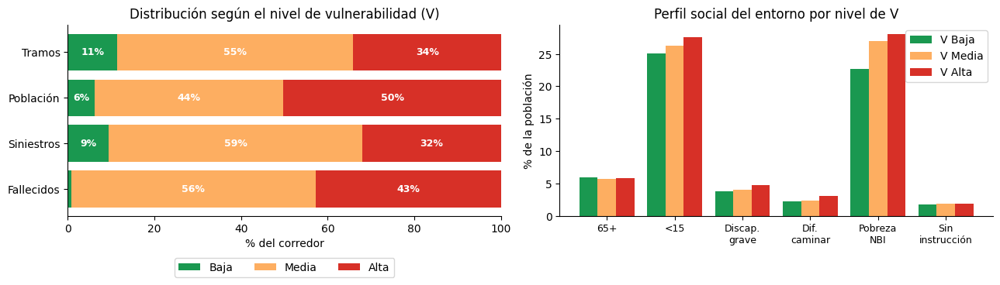

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
COL = {'Baja': '#1a9850', 'Media': '#fdae61', 'Alta': '#d73027'}
tv = tablas_pct['nivel_v'][['%_tramos', '%_poblacion', '%_siniestros', '%_fallecidos']].T * 100
izq = np.zeros(len(tv))
for n in ['Baja', 'Media', 'Alta']:
    axs[0].barh(['Tramos', 'Población', 'Siniestros', 'Fallecidos'], tv[n], left=izq, color=COL[n], label=n)
    for i, (l, v) in enumerate(zip(izq, tv[n])):
        if v >= 6: axs[0].text(l + v / 2, i, f'{v:.0f}%', ha='center', va='center', color='white', fontsize=9, fontweight='bold')
    izq += tv[n].values
axs[0].invert_yaxis(); axs[0].set_xlim(0, 100); axs[0].set_xlabel('% del corredor')
axs[0].set_title('Distribución según el nivel de vulnerabilidad (V)'); axs[0].legend(ncol=3, loc='lower center', bbox_to_anchor=(.5, -.35))
gv = grupo_v.T * 100
x = np.arange(len(gv)); a = 0.27
for i, n in enumerate(['Baja', 'Media', 'Alta']):
    axs[1].bar(x + (i - 1) * a, gv[n], a, color=COL[n], label=f'V {n}')
CORTO = {'Adultos mayores (65+)': '65+', 'Niños y adolescentes (<15)': '<15', 'Discapacidad grave': 'Discap.\ngrave',
         'Dificultad para caminar': 'Dif.\ncaminar', 'Pobreza por NBI': 'Pobreza\nNBI', 'Sin instrucción (15+)': 'Sin\ninstrucción'}
axs[1].set_xticks(x); axs[1].set_xticklabels([CORTO.get(t, t) for t in gv.index], fontsize=9)
axs[1].set_ylabel('% de la población'); axs[1].set_title('Perfil social del entorno por nivel de V'); axs[1].legend()
for ax in axs: ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); fig.savefig(OUT / 'porcentajes_por_vulnerabilidad.png', dpi=200, bbox_inches='tight'); plt.show()

## 15. Mapas interactivos por dimensión
Cada mapa colorea los tramos de verde (bajo) a rojo (alto). Al hacer clic en un tramo se ven los porcentajes que explican su valor.

In [ ]:
T = gpd.GeoDataFrame(R.merge(tramos[['tramo', 'geometry']], on='tramo'), geometry='geometry', crs=CRS_METROS).to_crs(4326)
cmap_dim = branca.colormap.LinearColormap(['#1a9850', '#fee08b', '#d73027'], vmin=0, vmax=1)
pc = lambda v: '—' if pd.isna(v) else f'{v:.0%}'
f2 = lambda v: f'{v:.2f}'
f0 = lambda v: f'{v:,.0f}'
sec_cerca = gpd.clip(sec, buf.union_all().buffer(1500)).to_crs(4326)   # sectores recortados a 1,5 km del eje

def capa_tramos(m, col, titulo, campos, show=True):
    fg = folium.FeatureGroup(name=titulo, show=show)
    for r in T.itertuples():
        filas = ''.join(f'<tr><td style="padding-right:8px">{et}</td><td><b>{fmt(getattr(r, c))}</b></td></tr>' for et, c, fmt in campos)
        html = (f'<div style="font-family:sans-serif;font-size:12px;min-width:280px"><b style="font-size:14px">{r.tramo}</b> · '
                f'{r.parroquia} · {r.longitud_m:.0f} m<br><i>{txt(r.referencia, 100)}</i><table>{filas}</table></div>')
        folium.GeoJson(r.geometry.__geo_interface__, style_function=lambda f, c=cmap_dim(getattr(r, col)): {'color': c, 'weight': 7, 'opacity': .9},
                       highlight_function=lambda f: {'weight': 12, 'color': '#000'},
                       tooltip=f'{r.tramo} · {titulo}: {getattr(r, col):.2f}', popup=folium.Popup(html, max_width=380)).add_to(fg)
    fg.add_to(m)

def capa_sectores(m, col, titulo, show=False):
    vmax = float(sec_cerca[col].quantile(.95)) or 1
    cm = branca.colormap.LinearColormap(['#fff7ec', '#fc8d59', '#7f0000'], vmin=0, vmax=vmax)
    folium.GeoJson(sec_cerca[['cod_sector', 'poblacion', col, 'geometry']], name=titulo, show=show,
                   style_function=lambda f: {'fillColor': cm(min(f['properties'][col] or 0, vmax)), 'fillOpacity': .55,
                                             'color': '#888', 'weight': .3},
                   tooltip=folium.GeoJsonTooltip(['cod_sector', 'poblacion', col],
                                                 aliases=['Sector', 'Población', titulo + ':'])).add_to(m)

def mapa_base(zoom=12):
    return folium.Map(location=[T.lat_centro.mean(), T.lon_centro.mean()], zoom_start=zoom, tiles=TILES_CARTO, attr=ATTR_CARTO)

def mapa_dimension(col, titulo, campos, sectores=()):
    m = mapa_base()
    for c, et in sectores:
        capa_sectores(m, c, et)
    capa_tramos(m, col, titulo, campos)
    cmap_dim.caption = titulo; cmap_dim.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    m.save(str(OUT / f'mapa_{col}.html'))
    return m

mapa_dimension('valor_h', 'Peligrosidad (H)', [
    ('H', 'valor_h', f2), ('Nivel', 'nivel_h', str), ('Siniestros', 'n_siniestros', f0),
    ('% velocidad', 'pct_velocidad', pc), ('% intersección', 'pct_interseccion', pc),
    ('% geometría vial', 'pct_geometria', pc), ('% nocturnos / visibilidad', 'pct_visibilidad', pc),
    ('Intersecciones OSM/km', 'intersecciones_km', lambda v: f'{v:.1f}'),
    ('H siniestros · entorno', 'h_siniestros', f2), ('', 'h_entorno', f2)])

In [ ]:
mapa_dimension('valor_e', 'Exposición (E)', [
    ('E', 'valor_e', f2), ('Nivel', 'nivel_e', str), ('Siniestros', 'n_siniestros', f0),
    ('Vehículos/km', 'vehiculos_km', f0), ('% hora pico', 'pct_hora_pico', pc), ('% peatonales', 'pct_peatonal', pc),
    ('Población (±300 m)', 'poblacion_influencia', f0), ('Densidad hab/km²', 'densidad_hab_km2', f0),
    ('Intermediación máx.', 'intermediacion_max', lambda v: f'{v:.3f}'),
    ('E siniestros · entorno', 'e_siniestros', f2), ('', 'e_entorno', f2)])

In [ ]:
mapa_dimension('valor_v', 'Vulnerabilidad (V)', [
    ('V', 'valor_v', f2), ('Nivel', 'nivel_v', str), ('Siniestros', 'n_siniestros', f0),
    ('Fallecidos', 'fallecidos', f0), ('Lesionados', 'lesionados', f0),
    ('% con usuarios vulnerables', 'pct_usuario_vulnerable', pc), ('% cruce sin protección', 'pct_cruce_inseguro', pc),
    ('Población (±300 m)', 'poblacion_influencia', f0), ('% 65+', 'pct_65mas', pc), ('% <15', 'pct_menor15', pc),
    ('% discapacidad grave', 'pct_discapacidad_grave', pc), ('% pobreza NBI', 'pct_pobreza_nbi', pc),
    ('NBI adentro · afuera', 'pct_nbi_adentro', pc), ('', 'pct_nbi_afuera', pc),
    ('65+ adentro · afuera', 'pct_65mas_adentro', pc), ('', 'pct_65mas_afuera', pc),
    ('V siniestros · entorno', 'v_siniestros', f2), ('', 'v_entorno', f2)],
    sectores=[('pct_pobreza_nbi', '% pobreza NBI'), ('pct_65mas', '% 65+'), ('pct_menor15', '% <15'),
              ('pct_discapacidad_grave', '% discapacidad grave')])

## 16. Mapa integrado: dimensiones, criticidad, red OSM, censo y siniestros
Usa el control de capas para cambiar de dimensión y mostrar u ocultar los sectores censales, las intersecciones más centrales y los siniestros.

In [ ]:
def barra(v):
    return (f'<div style="background:#eee;width:100px;height:8px;display:inline-block"><div style="background:{cmap_dim(v)};'
            f'width:{v*100:.0f}px;height:8px"></div></div> {v:.2f}')
def ficha(r):
    return f"""<div style="font-family:sans-serif;font-size:12px;width:350px">
    <b style="font-size:14px">{r.tramo}</b> · {r.parroquia} · {r.longitud_m:.0f} m · {r.nodo_inicio} → {r.nodo_fin}<br>
    <i>{txt(r.referencia, 110)}</i><hr style="margin:4px 0">
    <b>Siniestros:</b> {r.n_siniestros} · <b>Fallecidos:</b> {r.fallecidos} · <b>Lesionados:</b> {r.lesionados}<br>
    <b>H</b> {barra(r.valor_h)} {r.nivel_h}<br><b>E</b> {barra(r.valor_e)} {r.nivel_e}<br><b>V</b> {barra(r.valor_v)} {r.nivel_v}<hr style="margin:4px 0">
    <b>Criticidad ponderada:</b> {r.crit_ponderada:.2f} ({r.nivel_crit_ponderada}) · <b>multiplicada:</b> {r.crit_multiplicada:.2f}<hr style="margin:4px 0">
    <b>Entorno (±{RADIO_INFLUENCIA_M} m):</b> {r.poblacion_influencia:,} hab · 65+ {pc(r.pct_65mas)} · &lt;15 {pc(r.pct_menor15)} ·
    discapacidad {pc(r.pct_discapacidad_grave)} · NBI {pc(r.pct_pobreza_nbi)}<br>
    <b>NBI adentro / afuera:</b> {pc(r.pct_nbi_adentro)} / {pc(r.pct_nbi_afuera)} · <b>65+:</b> {pc(r.pct_65mas_adentro)} / {pc(r.pct_65mas_afuera)}<br>
    <b>Red:</b> {r.intersecciones} intersecciones OSM · intermediación máx. {r.intermediacion_max:.3f}</div>"""

mapa = mapa_base()
capa_sectores(mapa, 'pct_pobreza_nbi', 'Sectores · % pobreza NBI')
capa_sectores(mapa, 'pct_65mas', 'Sectores · % 65+')
for col, nombre, ver in [('crit_ponderada', 'Criticidad · ponderada', True), ('crit_multiplicada', 'Criticidad · multiplicada', False),
                         ('valor_h', 'H · Peligrosidad', False), ('valor_e', 'E · Exposición', False), ('valor_v', 'V · Vulnerabilidad', False)]:
    fg = folium.FeatureGroup(name=nombre, show=ver)
    for r in T.itertuples():
        folium.GeoJson(r.geometry.__geo_interface__, style_function=lambda f, c=cmap_dim(getattr(r, col)): {'color': c, 'weight': 7, 'opacity': .9},
                       highlight_function=lambda f: {'weight': 12, 'color': '#000'},
                       tooltip=f'{r.tramo} · {nombre}: {getattr(r, col):.2f}', popup=folium.Popup(ficha(r), max_width=390)).add_to(fg)
    fg.add_to(mapa)
fc = folium.FeatureGroup(name='Top 10 intermediación (OSM)', show=True)
for r in ranking.head(10).itertuples():
    folium.CircleMarker([r.latitud, r.longitud], radius=8, color='#7c3aed', fill=True, fill_opacity=.85,
                        tooltip=f'Nodo OSM {r.nodo_osm} · intermediación {r.intermediacion:.3f}').add_to(fc)
fc.add_to(mapa)
fs = folium.FeatureGroup(name='Siniestros (Dataset_Limpio)', show=False)
for s in gdl.to_crs(4326).itertuples():
    color = '#000' if s.fallecidos > 0 else ('#e66101' if s.lesionados > 0 else '#5e3c99')
    folium.CircleMarker([s.geometry.y, s.geometry.x], radius=3, color=color, fill=True, fill_opacity=.8,
                        tooltip=f'{s.id_siniestro} · {s.tipo_siniestro} · {s.fecha_hora:%Y-%m-%d %H:%M}').add_to(fs)
fs.add_to(mapa)
cmap_dim.caption = 'Valor (0 = bajo, 1 = alto)'; cmap_dim.add_to(mapa)
folium.LayerControl(collapsed=False).add_to(mapa)
mapa.save(str(OUT / 'mapa_integrado_urb02_hev.html'))
print('Mapa guardado:', (OUT / 'mapa_integrado_urb02_hev.html').resolve())
mapa

Mapa guardado: /content/resultados_urb02_perimetral_hev/mapa_integrado_urb02_hev.html


## 17. Mapa estático para el informe

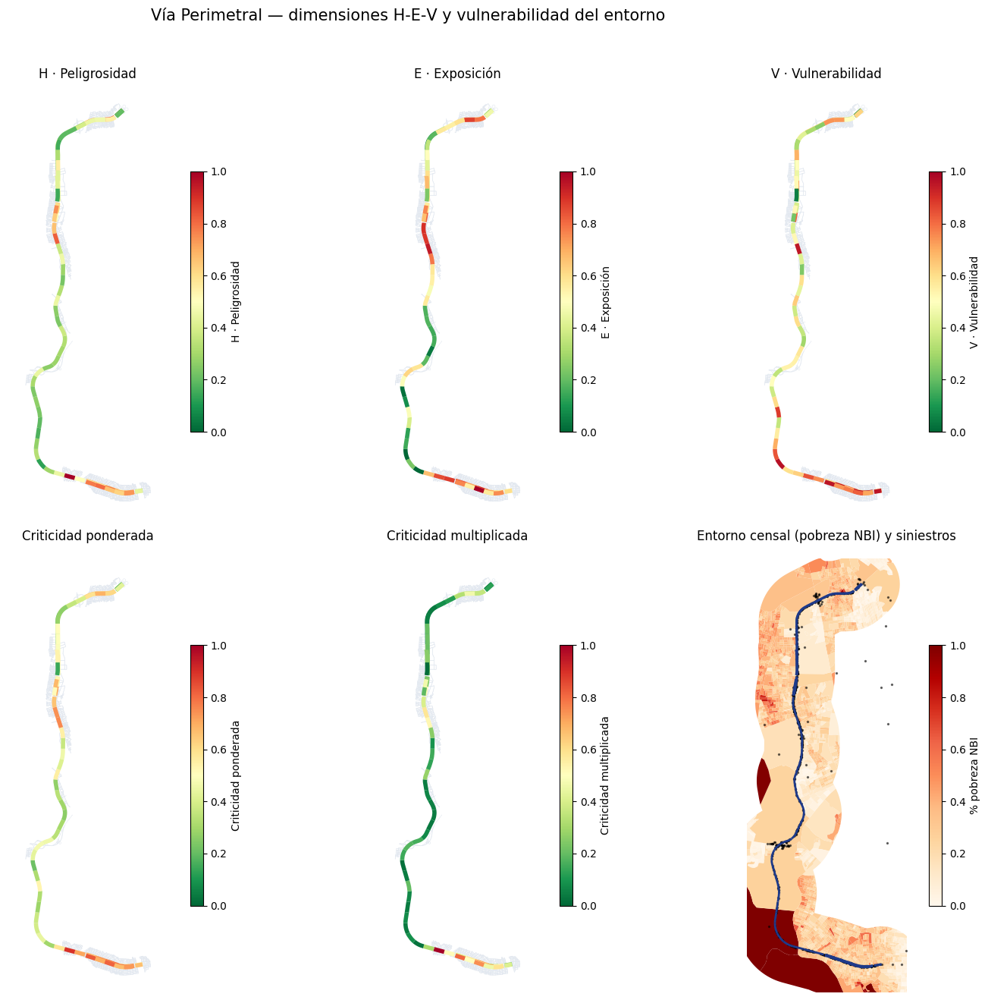

In [ ]:
Tm = T.to_crs(CRS_METROS)
fig, axs = plt.subplots(2, 3, figsize=(16, 13))
for ax, (col, tit) in zip(axs.flat[:5], [('valor_h', 'H · Peligrosidad'), ('valor_e', 'E · Exposición'), ('valor_v', 'V · Vulnerabilidad'),
                                          ('crit_ponderada', 'Criticidad ponderada'), ('crit_multiplicada', 'Criticidad multiplicada')]):
    aristas_osm.to_crs(CRS_METROS).plot(ax=ax, color='#e2e8f0', linewidth=.4)
    Tm.plot(ax=ax, column=col, cmap='RdYlGn_r', vmin=0, vmax=1, linewidth=4, legend=True,
            legend_kwds={'shrink': .6, 'label': tit})
    ax.set_title(tit); ax.set_axis_off()
ax = axs.flat[5]
sec_cerca.to_crs(CRS_METROS).plot(ax=ax, column='pct_pobreza_nbi', cmap='OrRd', linewidth=0, legend=True,
                                  legend_kwds={'shrink': .6, 'label': '% pobreza NBI'})
Tm.plot(ax=ax, color='#1e3a8a', linewidth=2); gdl.plot(ax=ax, color='black', markersize=2, alpha=.5)
ax.set_title('Entorno censal (pobreza NBI) y siniestros'); ax.set_axis_off()
x0, y0, x1, y1 = Tm.total_bounds; pad = 1200
for a in axs.flat:
    a.set_xlim(x0 - pad, x1 + pad); a.set_ylim(y0 - pad, y1 + pad)
fig.suptitle('Vía Perimetral — dimensiones H‑E‑V y vulnerabilidad del entorno', fontsize=15, y=1.01)
fig.tight_layout(); fig.savefig(OUT / 'mapa_estatico_hev_perimetral.png', dpi=200, bbox_inches='tight'); plt.show()

## 18. Resumen, exportaciones y conclusiones preliminares

In [ ]:
Tm[[c for c in Tm.columns]].to_crs(4326).to_file(OUT / 'tramos_hev_censo.geojson', driver='GeoJSON')
R.to_csv(OUT / 'tramos_hev_censo.csv', index=False, encoding='utf-8-sig')
perfil.to_csv(OUT / 'perfil_vulnerabilidad_corredor.csv', index=False, encoding='utf-8-sig')
comp.to_csv(OUT / 'vulnerabilidad_adentro_afuera_ciudad.csv', encoding='utf-8-sig')
censo_lados.drop(columns='clave').to_csv(OUT / 'censo_tramos_lados.csv', index=False, encoding='utf-8-sig')
with pd.ExcelWriter(OUT / 'porcentajes_por_nivel.xlsx') as xw:
    for k, t in tablas_pct.items():
        t.to_excel(xw, sheet_name=k[:31])
    grupo_v.to_excel(xw, sheet_name='perfil_social_por_V')
    comp.to_excel(xw, sheet_name='adentro_afuera_ciudad')
    lados_wide.to_excel(xw, sheet_name='lados_por_tramo', index=False)

# --- guardar en Supabase (requiere SUPABASE_SECRET_KEY y bypass de RLS) ---
try:
    ct = R[['tramo', 'n_sectores', 'poblacion_influencia', 'viviendas_influencia'] + list(PCT) + ['densidad_hab_km2']].copy()
    ct['sectores'] = None; ct['radio_m'] = RADIO_INFLUENCIA_M
    reemplazar('censo_tramos', ct.round(4), 'tramo')
except Exception as e:
    print(f'⚠ No se pudo guardar censo_tramos en Supabase debido a un error (puede ser RLS): {e}')

try:
    cl_ = censo_lados.rename(columns={'poblacion_influencia': 'poblacion', 'viviendas_influencia': 'viviendas'})
    cl_ = cl_[['tramo', 'lado', 'poblacion', 'viviendas'] + list(PCT) + ['densidad_hab_km2']].round(4)
    cl_['radio_m'] = RADIO_INFLUENCIA_M
    reemplazar('censo_tramos_lados', cl_, 'tramo')
except Exception as e:
    print(f'⚠ No se pudo guardar censo_tramos_lados en Supabase debido a un error (puede ser RLS): {e}')

try:
    COLS_URB02 = ['tramo', 'longitud_m', 'n_siniestros', 'fallecidos', 'lesionados', 'intersecciones', 'intersecciones_km',
                  'intermediacion_max', 'poblacion_influencia', 'densidad_hab_km2', 'pct_65mas', 'pct_menor15',
                  'pct_discapacidad_grave', 'pct_pobreza_nbi', 'pct_65mas_adentro', 'pct_65mas_afuera', 'pct_nbi_adentro',
                  'pct_nbi_afuera', 'h_siniestros', 'h_entorno', 'valor_h', 'nivel_h', 'e_siniestros', 'e_entorno', 'valor_e',
                  'nivel_e', 'v_siniestros', 'v_entorno', 'valor_v', 'nivel_v', 'crit_ponderada', 'crit_multiplicada',
                  'nivel_crit_ponderada', 'nivel_crit_multiplicada']
    u2 = R[COLS_URB02].copy()
    num = u2.select_dtypes('float').columns
    u2[num] = u2[num].round(4)
    u2['peso_entorno'] = PESO_ENTORNO
    reemplazar('urb02_tramos_hev', u2, 'tramo')
except Exception as e:
    print(f'⚠ No se pudo guardar urb02_tramos_hev en Supabase debido a un error de RLS o permisos: {e}')

alta_v = tablas_pct['nivel_v'].loc['Alta']
top = eficiencia.sort_values('reduccion_eficiencia_pct', ascending=False).iloc[0]
resumen_integral = pd.DataFrame([{
    'fecha_ejecucion': datetime.now().isoformat(timespec='seconds'),
    'km_eje': round(sum(g.length for g in eje) / 1000, 1), 'tramos_500m': len(R),
    'nodos_red_osm': G.number_of_nodes(), 'aristas_red_osm': G.number_of_edges(),
    'nodo_max_intermediacion': ranking.iloc[0]['nodo_osm'], 'intermediacion_maxima': round(ranking.iloc[0]['intermediacion'], 4),
    'mayor_reduccion_eficiencia_pct': round(top['reduccion_eficiencia_pct'], 1),
    'siniestros_unicos': len(gdl), 'siniestros_asignados_a_tramo': len(d),
    'poblacion_corredor_300m': round(pob_corr), **{f'corredor_{c}': round(tot[c].iat[0], 4) for c in PCT},
    'tramos_V_alta': int(alta_v['tramos']), 'pct_tramos_V_alta': round(alta_v['%_tramos'], 3),
    'pct_poblacion_en_V_alta': round(alta_v['%_poblacion'], 3), 'pct_fallecidos_en_V_alta': round(alta_v['%_fallecidos'], 3),
    'tramos_criticidad_alta': int((R.nivel_crit_ponderada == 'Alta').sum()),
    'nbi_adentro': round(comp.loc['Adentro (hacia la ciudad)', 'Pobreza por NBI'], 4),
    'nbi_afuera': round(comp.loc['Afuera (hacia la periferia)', 'Pobreza por NBI'], 4),
    'nbi_guayaquil_urbano': round(comp.loc['Guayaquil urbano', 'Pobreza por NBI'], 4),
    'brecha_nbi_afuera_menos_adentro_pp': round(brecha['Pobreza por NBI'], 1),
    'tramos_con_mas_pobreza_afuera': f'{n_mas} de {n_val}',
}])
display(resumen_integral.T.rename(columns={0: 'Valor'}))
resumen_integral.to_csv(OUT / 'resumen_integral_urb02_perimetral.csv', index=False, encoding='utf-8-sig')

top5 = R.sort_values('crit_ponderada', ascending=False).head(5)
print('Tramos más críticos (ponderada):')
for r in top5.itertuples():
    print(f'  {r.tramo} · {txt(r.referencia, 60)} · H {r.valor_h:.2f} · E {r.valor_e:.2f} · V {r.valor_v:.2f} · '
          f'{r.n_siniestros} siniestros · {r.poblacion_influencia:,} hab · NBI {pc(r.pct_pobreza_nbi)}')
print('\nArchivos generados en:', OUT.resolve())
print('INTERPRETACIÓN: H, E y V combinan lo observado en siniestros con el entorno (red OSM y censo).')
print('El censo describe a la población residente alrededor del tramo, no a las víctimas de los siniestros.')
print('LIMITACIONES: sin aforos de tráfico (no hay tasa por vehículo-km real); censo 2022 frente a siniestros 2024-2026;')
print('la intermediación es aproximada (muestra) y la asociación espacial usa umbrales exploratorios.')

✔ censo_tramos: 88 filas guardadas en Supabase
✔ censo_tramos_lados: 176 filas guardadas en Supabase
✔ urb02_tramos_hev: 88 filas guardadas en Supabase


,Valor
fecha_ejecucion,2026-11-23T02:27:04
km_eje,43.0
tramos_500m,88
nodos_red_osm,2307
aristas_red_osm,6072
nodo_max_intermediacion,595147871.0
intermediacion_maxima,0.2714
mayor_reduccion_eficiencia_pct,18.2
siniestros_unicos,876
siniestros_asignados_a_tramo,816


Tramos más críticos (ponderada):
  T040 · VÍA PERIMETRAL Y CALLE MARCELINO MARIDUEÑA · H 1.00 · E 0.85 · V 0.84 · 20 siniestros · 10,716 hab · NBI 29%
  T082 · VIA PERIMETRAL Y AV. 34 S-O, ALTURA DEL TUTI. · H 0.78 · E 0.76 · V 0.95 · 4 siniestros · 9,320 hab · NBI 28%
  T074 · Av. Perimetral y Av.29 - Sector Isla Trinitaria. · H 0.77 · E 0.93 · V 0.76 · 22 siniestros · 10,363 hab · NBI 25%
  T084 · Vía Perimetral y Av. Los Angeles · H 0.66 · E 1.00 · V 0.78 · 8 siniestros · 10,515 hab · NBI 25%
  T080 · AV. PERIMETRAL Y CALLE VICENTE ARNULFO ROSERO PALACIOS - ISL · H 0.69 · E 0.70 · V 0.99 · 9 siniestros · 10,871 hab · NBI 26%

Archivos generados en: /content/resultados_urb02_perimetral_hev
INTERPRETACIÓN: H, E y V combinan lo observado en siniestros con el entorno (red OSM y censo).
El censo describe a la población residente alrededor del tramo, no a las víctimas de los siniestros.
LIMITACIONES: sin aforos de tráfico (no hay tasa por vehículo-km real); censo 2022 frente a siniestros 